In [1]:
### standard libraries
import time
import numpy as np
import matplotlib.pyplot as plt
# import importlib

### other
import mrcfile

### my modules
from fast_volume_align_ot import utils, plots, transforms, signals, fle_3d, alignments

---

### Test cryo-EM volume

---

In [2]:
def fourier_downsample(array, factor=1, rescale=False):
    """Downsample array by cropping its Fourier transform (factor 2 would give 100pix -> 50pix)"""
    
    assert factor >= 1, "scale factor must be greater than 1"
    
    shape = array.shape
    center = [d//2 for d in shape]
    new_shape = [int(d / factor) for d in shape]
    
    F = np.fft.fftshift(np.fft.fftn(array))
    idx = tuple([slice(center[i] - new_shape[i]//2, center[i] + new_shape[i]//2) for i in range(len(shape))])
    F = F[idx] 
    
    if rescale:
        F = F * (np.product(new_shape) / np.product(shape))
    
    f_downsample = np.fft.ifftn(np.fft.ifftshift((F)))
    
    return f_downsample.real

-0.43449956 0.875363 

(240, 240, 240)
1.77


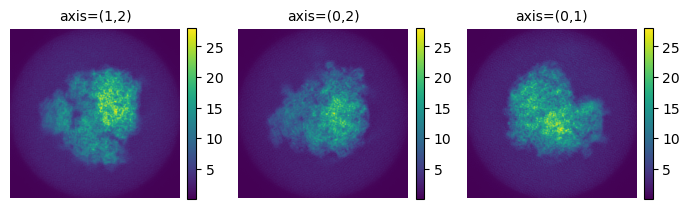

(80, 80, 80)
5.309999942779541


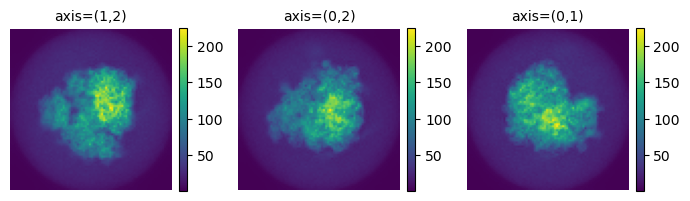

In [3]:
### Load the mrcfile and mask
### apply the mask, then downsample to volume

### EV: could crop the volume before downsampling
### EV: what about positive/negative value maps? (usually standardized??)

# data_file = 'Data/emd_11657.map'  # this volume has symmetry (?), a bit difficult
# mask_file = 'Data/emd_11657_msk_1.map'

data_file = 'Data/emd_2858.map'

mask = False


with mrcfile.open(data_file) as mrc:
    f = mrc.data
    voxel = mrc.voxel_size.x
    mrc.close()

if mask:
    with mrcfile.open(mask_file) as mrc:
        mask = mrc.data
        mrc.close()
    f = f * mask

print(np.amin(f), np.amax(f), '\n')
f = np.where(f>0, f, 0)

print(f.shape)
print(voxel)
plots.orthogonal_2D_projection_plot(f)

factor = 3  # EV: change this depending on volume size
f = fourier_downsample(f, factor)
voxel = voxel *factor

print(f.shape)
print(voxel)
plots.orthogonal_2D_projection_plot(f)

In [ ]:
np.random.seed(0)

M = f.shape[0]    # grid size LxLxL
d = 3             # dimensons

F = signals.Signal(f, d=3).preprocess_signals()[0]

print('mass = ', np.sum(F), '\n') 

## Rotates the structure F by random angles to produce structure G
omega = np.deg2rad(np.random.randint(0,360))
alpha = np.deg2rad(np.random.randint(0,360))
beta = np.deg2rad(np.random.randint(0,180))

# R_gt = transforms.rotate_zyz(omega, beta, alpha)
print('omega =', omega)
print('alpha =', alpha)
print('beta =', beta)
print('\n')

### TODO: CHANGE THESE THINGS TO MORE ACCURATE ROTATIONS (BECAUSE THIS GIVES ERRORS
### EVEN WITH GROUND TRUTH ROTATIONS). OPTIONS: 1) ASPIRE 2) SPHERICAL BESSEL EXACT STUFF
# print('\nRotated Volume\n')
G = transforms.rotate_voxel_zyz(F, omega, beta, alpha, order=1)
G = signals.Signal(G, d=3).preprocess_signals()[0]

t = time.time()
# F_icdf = transforms.Transform(F, d=3, apply_ramp=False).radon_transform()
# G_icdf = transforms.Transform(G, d=3, apply_ramp=False).radon_transform()
# F_icdf = transforms.Transform(F, d=3, apply_ramp=False).cdf_transform()
# G_icdf = transforms.Transform(G, d=3, apply_ramp=False).cdf_transform()
# F_icdf = transforms.Transform(F, d=3, apply_ramp=False, proj_type='BH').inverse_cdf_transform()
# G_icdf = transforms.Transform(G, d=3, apply_ramp=False, proj_type='BH').inverse_cdf_transform()
F_icdf = transforms.Transform(F, d=3, apply_ramp=False).inverse_cdf_transform()
G_icdf = transforms.Transform(G, d=3, apply_ramp=False).inverse_cdf_transform()
print('ICDF transforms: ', time.time() - t)

plots.orthogonal_2D_projection_plot(F)
plots.orthogonal_2D_projection_plot(G)

In [ ]:
plt.imshow(F_icdf[0, M//2, ...])
plt.show()
plt.imshow(G_icdf[0, M//2, ...])
plt.show()

In [ ]:
max_l = M//2
# max_l = M//4

fle = fle_3d.FLEBasis3D(M, M, 1e-6, max_l=max_l, mode="complex", force_real="True")

t1 = time.time()

c = alignments.align(F_icdf, G_icdf, fle)
c2 = transforms.rotate_zyz(omega, beta, alpha)

print("Timing of align:", time.time()-t1, '\n')
print(c)
print(c2.T)
print('\n')
print(np.linalg.norm(c-c2.T)/np.linalg.norm(c))

In [ ]:
# rotated = transforms.rotate_voxels_3d(G, c2.T)  # use the GT rotations
rotated = transforms.rotate_voxels_3d(G, c)

print("RELATIVE ERROR: ", np.linalg.norm(F - rotated) / np.linalg.norm(F))

plots.orthogonal_2D_projection_plot(F)
plots.orthogonal_2D_projection_plot(rotated)
plots.orthogonal_2D_projection_plot(F-rotated)

In [ ]:
g_est, b_est, a_est = transforms.rotmat_to_euler_zyz(c.T)

print('ground truth: ' , np.rad2deg([omega, beta, alpha]))

print('    estimate: ', np.round( np.rad2deg(transforms.rotmat_to_euler_zyz(c.T)) , 1))

---

### test non-overlapping volumnes

---

In [ ]:
### EV: test non-overlappinig volumes
###     need better volume than this though

np.random.seed(0)

M = 100
d = 3
sigma = 2

z = utils.generate_centered_gaussian(M, d=d, sigma=sigma)

f = transforms.translate_3d(z, 5, 10, 0)
f += transforms.translate_3d(z, -5, 10, 0) #* 0.5

g = transforms.translate_3d(z, 20, 10, 0)
g += transforms.translate_3d(z, -20, 10, 0) #* 0.5

omega = np.deg2rad(np.random.randint(0,360))
alpha = np.deg2rad(np.random.randint(0,360))
beta = np.deg2rad(np.random.randint(0,180))

print('omega =', omega)
print('alpha =', alpha)
print('beta =', beta)
print('\n')

F = signals.Signal(f, d=3).preprocess_signals()[0]

G = transforms.rotate_voxel_zyz(g, omega, beta, alpha, order=1)
G = signals.Signal(G, d=3).preprocess_signals()[0]

t = time.time()
# F_icdf = transforms.Transform(F, d=3, apply_ramp=False).radon_transform()
# G_icdf = transforms.Transform(G, d=3, apply_ramp=False).radon_transform()
# F_icdf = transforms.Transform(F, d=3, apply_ramp=False).cdf_transform()
# G_icdf = transforms.Transform(G, d=3, apply_ramp=False).cdf_transform()
F_icdf = transforms.Transform(F, d=3, apply_ramp=False).inverse_cdf_transform()
G_icdf = transforms.Transform(G, d=3, apply_ramp=False).inverse_cdf_transform()
print('ICDF transforms: ', time.time() - t)

plots.orthogonal_2D_projection_plot(F)
plots.orthogonal_2D_projection_plot(G)

In [ ]:
plt.imshow(F_icdf[0, 0, :, :])
plt.show()
plt.imshow(G_icdf[0, 0, :, :])
plt.show()

In [ ]:
max_l = M//2
# max_l = M//4

fle = fle_3d.FLEBasis3D(M, M, 1e-6, max_l=max_l, mode="complex", force_real="True")

t1 = time.time()

c = alignments.align(F_icdf, G_icdf, fle)
c2 = transforms.rotate_zyz(omega, beta, alpha)

print("Timing of align:", time.time()-t1, '\n')
# print(c)
# print(c2.T)
# print('\n')
# print(np.linalg.norm(c-c2.T)/np.linalg.norm(c))

In [ ]:
rotated = transforms.rotate_voxels_3d(G, c)

print("RELATIVE ERROR: ", np.linalg.norm(F - rotated) / np.linalg.norm(F))

plots.orthogonal_2D_projection_plot(F)
plots.orthogonal_2D_projection_plot(rotated)
plots.orthogonal_2D_projection_plot(F-rotated)
print('\n')
plots.orthogonal_2D_projection_plot(F - G)

In [ ]:
# g_est, b_est, a_est = transforms.rotmat_to_euler_zyz(c.T)

print('ground truth: ' , np.rad2deg([omega, beta, alpha]))

print('    estimate: ', np.round( np.rad2deg(transforms.rotmat_to_euler_zyz(c.T)), 2))

In [ ]:
# np.linalg.norm(F) * 2, np.linalg.norm(F) + np.linalg.norm(G), np.linalg.norm(F - G)

---

### test simulated heterogeneity cryo-EM volumes

---

In [ ]:
file1 = 'Data/het_models/0.mrc'   # first volume
file2 = 'Data/het_models/20.mrc'  

with mrcfile.open(file1, permissive=True) as mrc:
    v1 = mrc.data
    mrc.close()

with mrcfile.open(file2, permissive=True) as mrc:
    v2 = mrc.data
    mrc.close()

plots.orthogonal_2D_projection_plot(v1)
plots.orthogonal_2D_projection_plot(v2)
plots.orthogonal_2D_projection_plot(v1 - v2)

In [ ]:
np.random.seed(0)

M = f.shape[0]    # grid size LxLxL
d = 3             # dimensons

F = signals.Signal(v1, d=3).preprocess_signals()[0]

print('mass = ', np.sum(F), '\n') 

## Rotates the structure F by random angles to produce structure G
omega = np.deg2rad(np.random.randint(0,360))
alpha = np.deg2rad(np.random.randint(0,360))
beta = np.deg2rad(np.random.randint(0,180))

print('omega =', omega)
print('alpha =', alpha)
print('beta =', beta)
print('\n')

G = transforms.rotate_voxel_zyz(v2, omega, beta, alpha, order=1)
G = signals.Signal(G, d=3).preprocess_signals()[0]

t = time.time()
F_icdf = transforms.Transform(F, d=3, apply_ramp=False).inverse_cdf_transform()
G_icdf = transforms.Transform(G, d=3, apply_ramp=False).inverse_cdf_transform()
print('ICDF transforms: ', time.time() - t)

plots.orthogonal_2D_projection_plot(F)
plots.orthogonal_2D_projection_plot(G)
plots.orthogonal_2D_projection_plot(F - G)

In [ ]:
max_l = M//2
# max_l = M//4

fle = fle_3d.FLEBasis3D(M, M, 1e-6, max_l=max_l, mode="complex", force_real="True")

t1 = time.time()

c = alignments.align(F_icdf, G_icdf, fle)
c2 = transforms.rotate_zyz(omega, beta, alpha)

print("Timing of align:", time.time()-t1, '\n')
print(c)
print(c2.T)
print('\n')
print(np.linalg.norm(c-c2.T)/np.linalg.norm(c))

In [ ]:
rotated = transforms.rotate_voxels_3d(G, c)

print("RELATIVE ERROR: ", np.linalg.norm(F - rotated) / np.linalg.norm(F))

plots.orthogonal_2D_projection_plot(F)
plots.orthogonal_2D_projection_plot(rotated)
plots.orthogonal_2D_projection_plot(F-rotated)

In [ ]:
g_est, b_est, a_est = transforms.rotmat_to_euler_zyz(c.T)

print('ground truth: ' , np.rad2deg([omega, beta, alpha]))

print('    estimate: ', np.round( np.rad2deg(transforms.rotmat_to_euler_zyz(c.T)) , 1))